# From gene weights to model predictions

This companion interprets [gene_interactions.ipynb](gene_interactions.ipynb):
first understand what its gene coefficients mean, then use **two figures** to
ask whether penalties change individual predictions and whether adding genes
helps each classifier.

We use the saved coefficients and predictions; no models are refitted or tuned.
Coefficients were estimated with **130 training participants**. Both figures
use the same **61 test participants: 34 TB-positive and 27 TB-negative**.
These test data have already been examined during model exploration, so the
comparisons are descriptive. Rerun the preceding notebook if its inputs or
model settings change.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from scipy.special import expit
from sklearn.metrics import roc_auc_score

current = Path.cwd().resolve()
ROOT = next(p for p in [current, *current.parents]
            if (p / "Files_For_Manuscript").is_dir())
SOURCE = ROOT / "Figure_Output/Gene_Interactions/focused"
OUTPUT = ROOT / "Figure_Output/Gene_Cutoff_Interpretation/interpretation"
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED, BOOTSTRAPS = 87, 2000
BLUE, DARK = "#285F82", "#333333"
NONE = "Logistic GLM: no penalty"
PAPER = "Paper replica: no intercept, no penalty"
PENALTIES = {
    "L2 (Ridge)": "Logistic GLM: L2 (Ridge)",
    "L1 (Lasso)": "Logistic GLM: L1 (Lasso)",
    "Elastic net": "Logistic GLM: elastic net",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180, "font.family": "DejaVu Sans",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.7, "axes.grid": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
source_hashes = {}


def record_source(path):
    source_hashes[str(path.relative_to(ROOT))] = hashlib.sha256(path.read_bytes()).hexdigest()
    return path


def read_source(name):
    return pd.read_csv(record_source(SOURCE / name))


def read_json(path):
    return json.loads(record_source(path).read_text())


def save_figure(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"{name}.{suffix}", bbox_inches="tight")

### Check the saved results

Match participants by ID, reproduce the six-gene probabilities from the saved
weights, and verify test AUCs against the previous notebook. Check that the two
larger gene sets used the same recorded classifier settings.

In [2]:
metadata_path = ROOT / "Files_For_Manuscript/metadata.test.tsv"
metadata = pd.read_csv(metadata_path, sep="\t", index_col="sample_id")
record_source(metadata_path)
assert metadata.index.is_unique and set(metadata.tb) == {"positive", "negative"}
y = metadata.tb.eq("positive").astype(int).to_numpy()
assert len(y) == 61 and y.sum() == 34

probability_rows = read_source("logistic_control_probabilities.csv")
score_rows = read_source("prediction_scores.csv").query("split == 'test'")
reported_logistic = read_source("logistic_test_roc_results.csv").set_index("model")
reported_broad = read_source("gene_set_results.csv")
assert not probability_rows.duplicated(["sample_id", "model"]).any()
assert not score_rows.duplicated(["sample_id", "feature_set", "model"]).any()
for _, group in probability_rows.groupby("model"):
    assert set(group.sample_id) == set(metadata.index)
    np.testing.assert_array_equal(group.set_index("sample_id").loc[metadata.index, "tb_positive"], y)
for _, group in score_rows.groupby(["feature_set", "model"]):
    assert set(group.sample_id) == set(metadata.index)
    np.testing.assert_array_equal(group.set_index("sample_id").loc[metadata.index, "tb_positive"], y)
probabilities = probability_rows.pivot(
    index="sample_id", columns="model", values="probability"
).loc[metadata.index]
scores = score_rows.pivot(
    index="sample_id", columns=["feature_set", "model"], values="score"
).loc[metadata.index]
assert np.isfinite(probabilities.to_numpy()).all() and np.isfinite(scores.to_numpy()).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all().all()
for model in probabilities:
    np.testing.assert_allclose(
        roc_auc_score(y, probabilities[model]), reported_logistic.loc[model, "test_auc"],
        rtol=0, atol=1e-12,
    )
for row in reported_broad.itertuples():
    np.testing.assert_allclose(
        roc_auc_score(y, scores[(row.feature_set, row.model)]), row.test_auc,
        rtol=0, atol=1e-12,
    )

# Confirm the two gene-set experiments used the same recorded classifier settings.
model_settings = []
for name in ["de_genes_settings.json", "all_variable_genes_settings.json"]:
    path = SOURCE / name
    model_settings.append(read_json(path))
assert model_settings[0] == model_settings[1]
gene_counts = reported_broad.groupby("feature_set").n_features
assert gene_counts.nunique().eq(1).all()
gene_counts = gene_counts.first()


def pair_credit(values):
    # AUC is the mean of these credits: correct ordering = 1, tie = 0.5.
    values = np.asarray(values)
    positive, negative = values[y == 1, None], values[y == 0][None, :]
    return (positive > negative).astype(float) + 0.5 * (positive == negative)



# Confirm that coefficient units and predictions belong to these same fits.
coefficients = read_source("logistic_five_model_coefficients.csv").set_index("model")
control_coefficients = read_source("logistic_control_coefficients.csv").set_index("model")
scaling = read_source("logistic_coefficient_scaling.csv").set_index("gene")
logistic_settings = read_json(SOURCE / "logistic_control_settings.json")
train_metadata = pd.read_csv(record_source(ROOT / "Files_For_Manuscript/metadata.train.tsv"),
                             sep="\t", index_col="sample_id")
assert len(train_metadata) == 130 and train_metadata.index.is_unique
assert not set(train_metadata.index) & set(metadata.index)
paper_reference = ROOT / "Files_For_Manuscript/gene_cutoff_reference/paper_model"
paper_model = read_json(paper_reference / "model.json")
features = pd.read_csv(record_source(paper_reference / "paper_features.tsv"),
                       sep="\t", index_col="sample_id")
genes = paper_model["gene_names"]
gene_ids = paper_model["genes"]
assert list(coefficients.columns) == genes
assert scaling.loc[genes, "gene_id"].tolist() == gene_ids
train_x = features.loc[train_metadata.index, gene_ids].to_numpy()
test_x = features.loc[metadata.index, gene_ids].to_numpy()
np.testing.assert_array_equal(features.loc[metadata.index, "tb_binary"], y)
np.testing.assert_allclose(scaling.loc[genes, "training_sd"], train_x.std(axis=0, ddof=0))
center = train_x.mean(axis=0) if logistic_settings["standardization"]["with_mean"] else np.zeros(len(genes))
np.testing.assert_allclose(scaling.loc[genes, "training_center"], center, atol=1e-12)
test_z = (test_x - center) / scaling.loc[genes, "training_sd"].to_numpy()
for model in [NONE, *PENALTIES.values()]:
    weights = coefficients.loc[model, genes].to_numpy()
    np.testing.assert_allclose(weights, control_coefficients.loc[model, genes], atol=1e-12)
    np.testing.assert_allclose(
        expit(test_z @ weights + control_coefficients.loc[model, "Intercept"]),
        probabilities[model], rtol=0, atol=1e-12,
    )
paper_weights = np.array([paper_model["coefficients"][gene] for gene in gene_ids])
np.testing.assert_allclose(coefficients.loc["Paper replica: GFS", genes],
                           paper_weights * scaling.loc[genes, "training_sd"])
np.testing.assert_allclose(expit(test_x @ paper_weights + paper_model["intercept"]),
                           probabilities[PAPER], rtol=0, atol=1e-12)
print("Verified the five six-gene predictions, coefficient units, and 18 gene-set test AUCs.")

Verified the five six-gene predictions, coefficient units, and 18 gene-set test AUCs.


## What does a gene coefficient represent?

Expression is measured from RNA counts and transformed for modeling. A
**coefficient is a weight estimated from the training expression values and TB
labels**. Logistic regression fits the six weights jointly to minimize log loss;
L2 penalizes squared weights, L1 penalizes absolute weights, and elastic net
combines them.

In the preceding notebook, all five models' coefficients are expressed per
**one training standard deviation (SD) of VST expression**:

$$
\log\!\left(\frac{p}{1-p}\right)=b+\sum_j\beta_jz_j,
\qquad z_j=\frac{x_j-\mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}}.
$$

Here $p$ is predicted TB probability, $b$ is the intercept, and $z_j$ is scaled
expression. Holding the other five genes fixed, a one-SD increase in gene $j$
changes predicted log odds by $\beta_j$ and multiplies predicted odds by
$e^{\beta_j}$. **Positive means higher predicted odds; negative means lower;
zero means no contribution in that fitted model.** A participant's contribution
is $\beta_jz_j$, which also depends on their expression.

Use the **L2 model as a worked example** below. Coefficients are model weights,
not expression fold changes or percentages of biological importance. Correlated
genes can redistribute those weights. These estimates have no coefficient
confidence intervals and do not establish causal effects or gene interactions.

In [3]:
l2_weights = coefficients.loc[PENALTIES["L2 (Ridge)"], genes]
coefficient_example = pd.DataFrame({
    "gene": genes,
    "coefficient": l2_weights.to_numpy(),
    "odds_multiplier_per_training_sd": np.exp(l2_weights.to_numpy()),
})
coefficient_example.to_csv(OUTPUT / "coefficient_reading_example.csv", index=False)
table_lines = [
    "| Gene | Coefficient β | Odds multiplier for +1 training SD |",
    "|---|---:|---:|",
]
table_lines += [f"| {r.gene} | {r.coefficient:+.2f} | {r.odds_multiplier_per_training_sd:.2f} |"
                for r in coefficient_example.itertuples()]
display(Markdown("\n".join(table_lines)))
gbp5_beta = l2_weights["GBP5"]
gbp5_odds = np.exp(gbp5_beta)
gbp5_sd = scaling.loc["GBP5", "training_sd"]
example_p = expit(np.log(0.20 / 0.80) + gbp5_beta)
display(Markdown(
    f"**Example:** GBP5 has β = **{gbp5_beta:+.2f}**. Increasing its expression by "
    f"one training SD ({gbp5_sd:.2f} VST units), with the other genes fixed, "
    f"multiplies predicted TB odds by **{gbp5_odds:.2f}**. For an illustrative "
    f"starting probability of 0.20, this gives **{example_p:.2f}**, not "
    f"{gbp5_odds:.2f} times the probability. Odds mean p / (1 − p)."
))

| Gene | Coefficient β | Odds multiplier for +1 training SD |
|---|---:|---:|
| GBP5 | +1.52 | 4.59 |
| BNIP3L | -0.33 | 0.72 |
| KLF6 | -0.52 | 0.59 |
| DYSF | +0.69 | 2.00 |
| LASP1 | -0.14 | 0.87 |
| PCBP1 | +0.69 | 2.00 |

**Example:** GBP5 has β = **+1.52**. Increasing its expression by one training SD (1.05 VST units), with the other genes fixed, multiplies predicted TB odds by **4.59**. For an illustrative starting probability of 0.20, this gives **0.53**, not 4.59 times the probability. Odds mean p / (1 − p).

## 1. How much does regularization change predicted TB probability?

The previous notebook shows that penalties change the fitted gene weights.
Here we ask what that means for a participant: **how far does their predicted
TB probability move when we use a penalty?** Compare each penalized fit with
the new unpenalized fit, using the same six genes, training participants, and
intercept setting. The coefficients and intercept may change together.

We measure the size of the change in **percentage points**. A prediction moving
from **40% to 43%**, or from **40% to 37%**, changes by **3 percentage points**.
We count increases and decreases equally because this question is about the
amount of change.

**Read the figure:** each dot is one of the 61 test participants. A dot at zero
means no change; farther right means a larger change. The black mark shows the
median: half the participants have a change no larger than that value.
This measures how much predictions change, **not whether they become more accurate**.

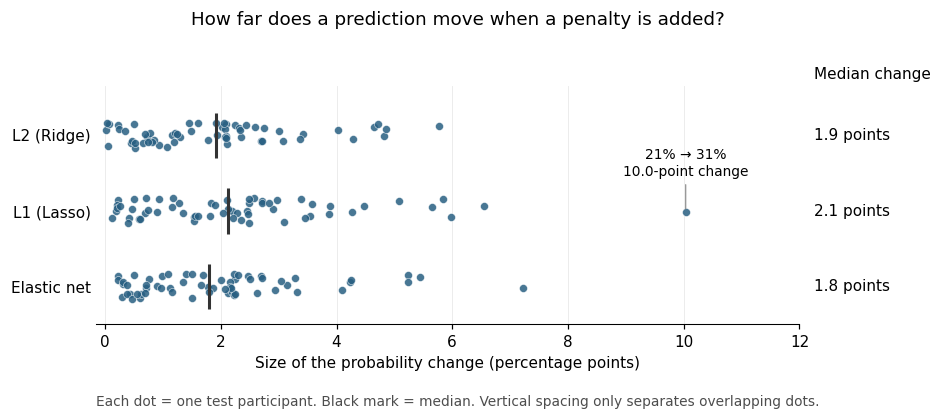

**What this tells us:** the median change is **1.8–2.1 percentage points** across the three penalties: about two points for the middle participant. Some predictions move more. The largest change is under **L1 (Lasso)**, from **21.0% to 31.0%** (**10.0 percentage points**).

Thus, changing the fitting penalty changes the gene weights, but typically moves the predicted probability by about two points in these test participants. This does not tell us which model is more accurate or whether its probabilities are well calibrated; it measures sensitivity to the choice of penalty.

In [4]:
baseline = probabilities[NONE].to_numpy()
prediction_rows, participant_rows = [], []
display_offsets = np.random.default_rng(SEED).uniform(-0.17, 0.17, size=len(y))

for label, model in PENALTIES.items():
    candidate = probabilities[model].to_numpy()
    signed_change_pp = 100 * (candidate - baseline)
    absolute_change_pp = np.abs(signed_change_pp)
    prediction_rows.append({
        "penalty": label, "model": model, "participants": len(y),
        "median_absolute_change_pp": np.median(absolute_change_pp),
        "mean_absolute_change_pp": absolute_change_pp.mean(),
        "max_absolute_change_pp": absolute_change_pp.max(),
    })
    participant_rows.append(pd.DataFrame({
        "sample_id": metadata.index, "penalty": label, "model": model,
        "unpenalized_probability": baseline, "penalized_probability": candidate,
        "signed_change_pp": signed_change_pp, "absolute_change_pp": absolute_change_pp,
    }))

prediction_changes = pd.DataFrame(prediction_rows)
participant_changes = pd.concat(participant_rows, ignore_index=True)
assert not participant_changes.duplicated(["sample_id", "model"]).any()
assert participant_changes.groupby("model").size().eq(len(y)).all()
np.testing.assert_allclose(
    participant_changes.absolute_change_pp,
    100 * np.abs(participant_changes.penalized_probability - participant_changes.unpenalized_probability),
)
prediction_changes.to_csv(OUTPUT / "regularization_prediction_agreement.csv", index=False)
participant_changes.to_csv(OUTPUT / "regularization_probability_changes_by_participant.csv", index=False)

figure, axis = plt.subplots(figsize=(9.4, 3.8))
for position, row in enumerate(prediction_changes.itertuples()):
    changes = participant_changes.loc[participant_changes.model.eq(row.model), "absolute_change_pp"]
    axis.scatter(changes, position + display_offsets, s=27, color=BLUE,
                 edgecolors="white", linewidths=0.35, alpha=0.85, zorder=3)
    axis.vlines(row.median_absolute_change_pp, position - 0.30, position + 0.30,
                color=DARK, linewidth=2, zorder=4)
    axis.text(1.02, position, f"{row.median_absolute_change_pp:.1f} points",
               transform=axis.get_yaxis_transform(), va="center", fontsize=10)

largest = participant_changes.loc[participant_changes.absolute_change_pp.idxmax()]
largest_position = list(PENALTIES).index(largest.penalty)
largest_offset = display_offsets[metadata.index.get_loc(largest.sample_id)]
axis.annotate(
    f"{largest.unpenalized_probability:.0%} → {largest.penalized_probability:.0%}\n"
    f"{largest.absolute_change_pp:.1f}-point change",
    xy=(largest.absolute_change_pp, largest_position + largest_offset),
    xytext=(largest.absolute_change_pp, largest_position - 0.43),
    ha="center", va="bottom", fontsize=9,
    arrowprops={"arrowstyle": "-", "color": "0.5", "linewidth": 0.7},
)
maximum_x = max(6, np.ceil(participant_changes.absolute_change_pp.max() / 2) * 2)
axis.set(
    yticks=np.arange(len(PENALTIES)), yticklabels=list(PENALTIES),
    xlim=(-0.15, maximum_x), ylim=(len(PENALTIES) - 0.5, -0.65),
    xlabel="Size of the probability change (percentage points)",
)
axis.set_xticks(np.arange(0, maximum_x + 0.1, 2))
axis.tick_params(axis="y", length=0)
axis.spines["left"].set_visible(False)
axis.set_axisbelow(True)
axis.grid(axis="x", color="0.92", linewidth=0.6)
axis.text(1.02, 1.03, "Median change", transform=axis.transAxes, fontsize=10)
figure.suptitle("How far does a prediction move when a penalty is added?", fontsize=12, y=0.98)
figure.text(0.5, 0.035,
             "Each dot = one test participant. Black mark = median. Vertical spacing only separates overlapping dots.",
             ha="center", fontsize=9, color="0.3")
figure.subplots_adjust(left=0.15, right=0.83, bottom=0.23, top=0.80)
save_figure(figure, "regularization_prediction_agreement")
plt.show()

medians = prediction_changes.median_absolute_change_pp
display(Markdown(
    f"**What this tells us:** the median change is **{medians.min():.1f}–{medians.max():.1f} "
    "percentage points** across the three penalties: about two points for the middle "
    "participant. Some predictions move more. The largest change is under "
    f"**{largest.penalty}**, from **{largest.unpenalized_probability:.1%} to "
    f"{largest.penalized_probability:.1%}** "
    f"(**{largest.absolute_change_pp:.1f} percentage points**).\n\n"
    "Thus, changing the fitting penalty changes the gene weights, but typically moves "
    "the predicted probability by about two points in these test participants. "
    "This does not tell us which model is more accurate or whether its probabilities "
    "are well calibrated; it measures sensitivity to the choice of penalty."
))

## 2. Does adding genes improve the same classifier?

Each row compares **142 DE genes** with **52,990 variable genes** for the same
classifier and test participants, using the same training-fitted VST protocol
and classifier settings. The six-gene experiment uses different preprocessing
and is not included here.

The two markers show the actual test AUCs: farther right is better ranking.
The right column gives **AUC with all genes minus AUC with DE genes**, with a
95% paired bootstrap interval from 2,000 resamples of the same participants
for both predictions, separately within TB status. These intervals describe
test-sample uncertainty for the fitted models; they do not include training
uncertainty, cohort clustering, or adjustment for multiple comparisons.

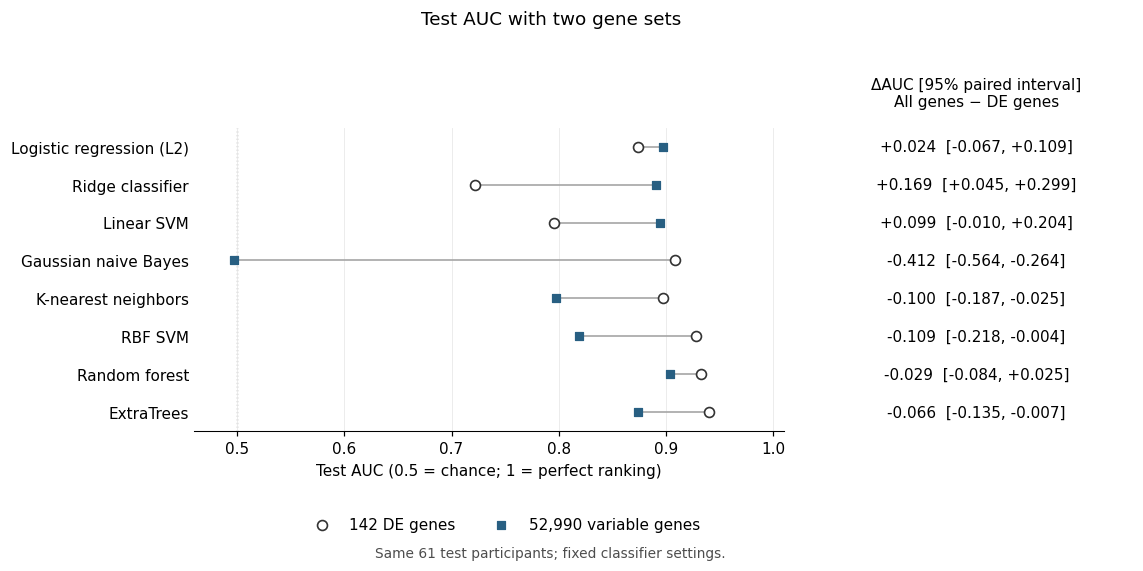

**Interpretation:** adding genes raises observed AUC for **3** classifiers and lowers it for **5**; **3 of 8** paired intervals include zero. The benefit of more genes depends on the classifier in these data. This does not identify whether noise, correlated genes, or model settings explain a change. The dummy classifier is omitted because both AUCs are 0.5.

In [5]:
model_labels = {
    "LogisticRegression": "Logistic regression (L2)",
    "RidgeClassifier": "Ridge classifier",
    "LinearSVC": "Linear SVM",
    "GaussianNB": "Gaussian naive Bayes",
    "KNeighborsClassifier": "K-nearest neighbors",
    "SVC": "RBF SVM",
    "RandomForestClassifier": "Random forest",
    "ExtraTreesClassifier": "ExtraTrees",
}
random = np.random.default_rng(SEED)
n_positive, n_negative = int(y.sum()), int((y == 0).sum())
positive_draws = random.integers(n_positive, size=(BOOTSTRAPS, n_positive))
negative_draws = random.integers(n_negative, size=(BOOTSTRAPS, n_negative))
gene_set_rows = []
for model, label in model_labels.items():
    de = pair_credit(scores[("DE genes", model)])
    all_genes = pair_credit(scores[("All variable genes", model)])
    difference = all_genes - de
    # Resample participants, not the 918 pair entries independently.
    draws = difference[positive_draws[:, :, None], negative_draws[:, None, :]].mean(axis=(1, 2))
    lower, upper = np.quantile(draws, [0.025, 0.975])
    gene_set_rows.append({
        "model": model, "label": label, "de_auc": de.mean(), "all_genes_auc": all_genes.mean(),
        "auc_change": difference.mean(), "lower_95": lower, "upper_95": upper,
    })
gene_set_changes = pd.DataFrame(gene_set_rows)
gene_set_changes.to_csv(OUTPUT / "gene_set_paired_auc.csv", index=False)


# Fixed classifier order, with paired endpoints and uncertainty in an aligned column.
figure, (axis, interval_axis) = plt.subplots(
    1, 2, figsize=(10.8, 5.1), sharey=True,
    gridspec_kw={"width_ratios": [3.2, 1.7]},
)
positions = np.arange(len(gene_set_changes))
axis.hlines(positions, gene_set_changes.de_auc, gene_set_changes.all_genes_auc,
            color="0.65", linewidth=1.1, zorder=1)
axis.scatter(gene_set_changes.de_auc, positions, s=42, marker="o",
             facecolors="white", edgecolors=DARK, linewidths=1.1, zorder=3,
             label=f"{gene_counts['DE genes']:,} DE genes")
axis.scatter(gene_set_changes.all_genes_auc, positions, s=32, marker="s",
             facecolors=BLUE, edgecolors=BLUE, linewidths=0.8, zorder=4,
             label=f"{gene_counts['All variable genes']:,} variable genes")
axis.axvline(0.5, color="0.6", linestyle=":", linewidth=0.9, zorder=0)
axis.set(yticks=positions, yticklabels=gene_set_changes.label,
         xlim=(0.46, 1.01), ylim=(len(positions) - 0.5, -0.5),
         xlabel="Test AUC (0.5 = chance; 1 = perfect ranking)")
axis.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
axis.tick_params(axis="y", length=0)
axis.spines["left"].set_visible(False)
axis.set_axisbelow(True)
axis.grid(axis="x", color="0.92", linewidth=0.6)
interval_axis.set_xlim(0, 1)
interval_axis.axis("off")
interval_axis.set_title("ΔAUC [95% paired interval]\nAll genes − DE genes", fontsize=10, pad=14)
for position, row in enumerate(gene_set_changes.itertuples()):
    interval_axis.text(0.5, position,
                       f"{row.auc_change:+.3f}  [{row.lower_95:+.3f}, {row.upper_95:+.3f}]",
                       ha="center", va="center", fontsize=10)
figure.suptitle("Test AUC with two gene sets", fontsize=12, y=0.99)
handles, labels = axis.get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.46, 0.035),
               ncol=2, frameon=False, fontsize=10)
figure.text(0.5, 0.015, f"Same {len(y)} test participants; fixed classifier settings.",
             ha="center", fontsize=9, color="0.3")
figure.subplots_adjust(left=0.20, right=0.99, bottom=0.24, top=0.78, wspace=0.08)
save_figure(figure, "gene_set_paired_auc")
plt.show()

n_lower = int(gene_set_changes.auc_change.lt(0).sum())
n_higher = int(gene_set_changes.auc_change.gt(0).sum())
n_crossing = int((gene_set_changes.lower_95.le(0) & gene_set_changes.upper_95.ge(0)).sum())
display(Markdown(
    f"**Interpretation:** adding genes raises observed AUC for **{n_higher}** classifiers "
    f"and lowers it for **{n_lower}**; **{n_crossing} of {len(gene_set_changes)}** paired "
    "intervals include zero. The benefit of more genes depends on the classifier in "
    "these data. This does not identify whether noise, correlated genes, or model "
    "settings explain a change. The dummy classifier is omitted because both AUCs are 0.5."
))

## What this tells us

**Gene coefficients describe how a model uses expression. The first figure
shows how much its predictions change when the fitting penalty changes.**
It measures the size of a prediction change, not an improvement in accuracy.
The second figure compares ranking performance: adding more genes does not
consistently improve the same classifier on these test participants.

The figures, numeric tables, and input provenance are saved in
`Figure_Output/Gene_Cutoff_Interpretation/interpretation/`.

In [6]:
provenance = {
    "source_notebook": "Scripts_For_Manuscript/gene_interactions.ipynb",
    "source_sha256": source_hashes,
    "training_participants": len(train_metadata), "test_participants": len(y),
    "tb_positive": n_positive, "tb_negative": n_negative,
    "coefficient_units": "Natural log odds of TB per one training SD of VST expression",
    "gene_counts": {name: int(count) for name, count in gene_counts.items()},
    "bootstrap": {"seed": SEED, "repeats": BOOTSTRAPS, "confidence_level": 0.95,
                  "sampling": "Paired participants, stratified by TB status"},
    "figure_names": ["regularization_prediction_agreement", "gene_set_paired_auc"],
    "new_model_fits": 0,
}
_ = (OUTPUT / "input_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")